In [1]:
import sys
print(sys.version)

3.10.21 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:35:39) [MSC v.1942 64 bit (AMD64)]


## Importing Libraries


In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## Data Preprocessing

### Training image preprocessing

In [3]:
training_set = tf.keras.utils.image_dataset_from_directory(
    'train',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
)

Found 70295 files belonging to 38 classes.


### Validation image preprocessing

In [11]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
)

Found 17572 files belonging to 38 classes.


### To avoid Overshooting
1. Choose small learning rate (we are taking 0.0001)
2. There may be a chance of underfiitng , so increase number of neurons
3. Add more Covulation layer to extract more feature from images, there may be possibility that model is unable to capture relevant features or model is confusing due to lack of features

### Building Model

In [5]:
from tensorflow.keras.layers import Dense,Conv2D,MaxPool2D,Flatten,Dropout
from tensorflow.keras.models import Sequential

In [6]:
model = Sequential()

In [7]:
## Building convolution layer

In [8]:
model.add(Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
model.add(Conv2D(filters=32,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))


In [9]:
model.add(Conv2D(filters=64,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
model.add(Conv2D(filters=64,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [10]:
model.add(Conv2D(filters=128,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
model.add(Conv2D(filters=128,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [11]:
model.add(Conv2D(filters=256,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
model.add(Conv2D(filters=256,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [12]:
model.add(Conv2D(filters=512,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
model.add(Conv2D(filters=512,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [13]:
model.add(Dropout(0.25)) ##to avoid overfitting

In [14]:
model.add(Flatten())

In [15]:
model.add(Dense(units=1500,activation='relu'))

In [16]:
model.add(Dropout(0.25))

In [17]:
model.add(Dense(units=38, activation='softmax'))

## Compiling model

In [18]:
model.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [19]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 128, 128, 32)      896       
                                                                 
 conv2d_1 (Conv2D)           (None, 126, 126, 32)      9248      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 63, 63, 32)       0         
 )                                                               
                                                                 
 conv2d_2 (Conv2D)           (None, 63, 63, 64)        18496     
                                                                 
 conv2d_3 (Conv2D)           (None, 61, 61, 64)        36928     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 30, 30, 64)       0         
 2D)                                                    

### Training the model


In [20]:
training_history = model.fit(x=training_set,validation_data=validation_set,epochs=10)

Epoch 1/10
2197/2197 [==============================] - 197s 85ms/step - loss: 1.2570 - accuracy: 0.6283 - val_loss: 0.5578 - val_accuracy: 0.8247
Epoch 2/10
2197/2197 [==============================] - 186s 84ms/step - loss: 0.4125 - accuracy: 0.8683 - val_loss: 0.2394 - val_accuracy: 0.9241
Epoch 3/10
2197/2197 [==============================] - 196s 89ms/step - loss: 0.2474 - accuracy: 0.9201 - val_loss: 0.1870 - val_accuracy: 0.9374
Epoch 4/10
2197/2197 [==============================] - 226s 103ms/step - loss: 0.1670 - accuracy: 0.9450 - val_loss: 0.2061 - val_accuracy: 0.9314
Epoch 5/10
2197/2197 [==============================] - 221s 100ms/step - loss: 0.1266 - accuracy: 0.9581 - val_loss: 0.1635 - val_accuracy: 0.9475
Epoch 6/10
2197/2197 [==============================] - 195s 89ms/step - loss: 0.0984 - accuracy: 0.9680 - val_loss: 0.2206 - val_accuracy: 0.9327
Epoch 7/10
2197/2197 [==============================] - 194s 88ms/step - loss: 0.0809 - accuracy: 0.9730 - val_loss:

### Model Evaluation


In [21]:
#Model Evaluation on Training set
train_loss,train_acc = model.evaluate(training_set)

2197/2197 [==============================] - 64s 29ms/step - loss: 0.0289 - accuracy: 0.9905


In [22]:
print(train_loss,train_acc)

0.02891995944082737 0.9905398488044739


In [24]:
#Model Evaluation on Validation set
val_loss,val_acc = model.evaluate(validation_set)

550/550 [==============================] - 15s 27ms/step - loss: 0.1268 - accuracy: 0.9630


### Saving 

In [27]:
model.save("trained_model.keras")

In [28]:
training_history.history

{'loss': [1.2569684982299805,
  0.4124726951122284,
  0.24739374220371246,
  0.16700305044651031,
  0.1266172081232071,
  0.09838959574699402,
  0.08090206980705261,
  0.0684705451130867,
  0.0604766421020031,
  0.05320282652974129],
 'accuracy': [0.6282950639724731,
  0.8682978749275208,
  0.920136570930481,
  0.9450316429138184,
  0.9580766558647156,
  0.9680062532424927,
  0.9729568362236023,
  0.9780069589614868,
  0.9808521270751953,
  0.9828579425811768],
 'val_loss': [0.5577764511108398,
  0.23935739696025848,
  0.18698784708976746,
  0.20605690777301788,
  0.16345570981502533,
  0.22055937349796295,
  0.17741450667381287,
  0.13777899742126465,
  0.15402507781982422,
  0.12675628066062927],
 'val_accuracy': [0.8247211575508118,
  0.9240837693214417,
  0.9374004006385803,
  0.9313681125640869,
  0.9475301504135132,
  0.9326769709587097,
  0.9449692964553833,
  0.961586594581604,
  0.9550421237945557,
  0.9629524350166321]}

In [30]:
#Recording history in json for visualization
import json
with open("training_hist.json","w") as f:
    json.dump(training_history.history,f)

In [39]:
training_history.history['val_accuracy']

[0.8247211575508118,
 0.9240837693214417,
 0.9374004006385803,
 0.9313681125640869,
 0.9475301504135132,
 0.9326769709587097,
 0.9449692964553833,
 0.961586594581604,
 0.9550421237945557,
 0.9629524350166321]

## Accuracy Visualization

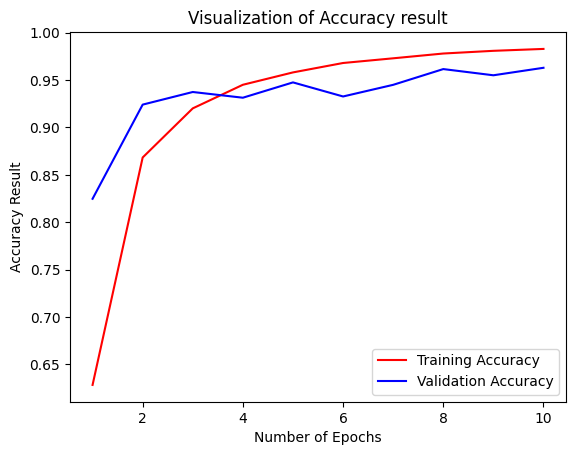

In [43]:
epochs=[ i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='red',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='blue',label='Validation Accuracy')
plt.xlabel("Number of Epochs")
plt.ylabel("Accuracy Result")
plt.title("Visualization of Accuracy result")
plt.legend()
plt.show()

### other metrics for model evaluation

In [12]:
class_name = validation_set.class_names
class_name

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

In [2]:
test_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=False,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
)

Found 17572 files belonging to 38 classes.


In [4]:
y_pred = model.predict(test_set)
y_pred,y_pred.shape

550/550 [==============================] - 22s 23ms/step


(array([[9.9999845e-01, 6.4547191e-07, 2.7553571e-10, ..., 5.3820101e-15,
         1.4646356e-13, 7.7560766e-13],
        [9.7219884e-01, 2.7745808e-02, 4.6364107e-08, ..., 9.2556674e-12,
         2.3846516e-10, 8.9067989e-11],
        [9.9999964e-01, 3.0495119e-07, 4.9310864e-12, ..., 1.2918797e-17,
         2.2694516e-14, 2.0502918e-13],
        ...,
        [4.4244730e-06, 2.1275002e-06, 6.4351181e-03, ..., 8.3939125e-07,
         1.0151889e-06, 9.6827817e-01],
        [8.9521626e-11, 1.0973686e-11, 1.5656396e-07, ..., 1.9234037e-09,
         3.1922612e-10, 9.9999094e-01],
        [1.4560590e-13, 1.1488842e-13, 3.3034058e-11, ..., 3.7811770e-13,
         5.0038528e-12, 9.9999237e-01]], dtype=float32),
 (17572, 38))

In [5]:
predicted_categories = tf.argmax(y_pred, axis=1)

In [6]:
predicted_categories

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], dtype=int64)>

In [7]:
true_categories = tf.concat([y for x,y in test_set],axis=0)
true_categories

<tf.Tensor: shape=(17572, 38), dtype=float32, numpy=
array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.]], dtype=float32)>

In [8]:
Y_true = tf.argmax(true_categories, axis=1)
Y_true

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], dtype=int64)>

In [14]:
from sklearn.metrics import classification_report,confusion_matrix

In [13]:
print(classification_report(Y_true,predicted_categories,target_names=class_name))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.97      0.96      0.97       504
                                 Apple___Black_rot       0.98      0.99      0.98       497
                          Apple___Cedar_apple_rust       0.95      0.98      0.96       440
                                   Apple___healthy       0.97      0.95      0.96       502
                               Blueberry___healthy       0.98      0.96      0.97       454
          Cherry_(including_sour)___Powdery_mildew       0.99      0.98      0.98       421
                 Cherry_(including_sour)___healthy       0.94      1.00      0.97       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.95      0.92      0.93       410
                       Corn_(maize)___Common_rust_       1.00      0.99      0.99       477
               Corn_(maize)___Northern_Leaf_Blight       0.94      0.97      0.

In [11]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
print(tf.config.list_logical_devices('GPU'))

[LogicalDevice(name='/device:GPU:0', device_type='GPU')]


In [3]:
model = tf.keras.models.load_model("trained_model.h5")

In [16]:
cn = confusion_matrix(Y_true,predicted_categories)
cn

array([[483,   2,   0, ...,   0,   0,   0],
       [  0, 492,   0, ...,   0,   0,   0],
       [  1,   0, 431, ...,   0,   0,   0],
       ...,
       [  0,   0,   0, ..., 483,   1,   0],
       [  0,   0,   0, ...,   0, 445,   0],
       [  0,   0,   1, ...,   0,   0, 472]], dtype=int64)

### Confusion matrix visualization


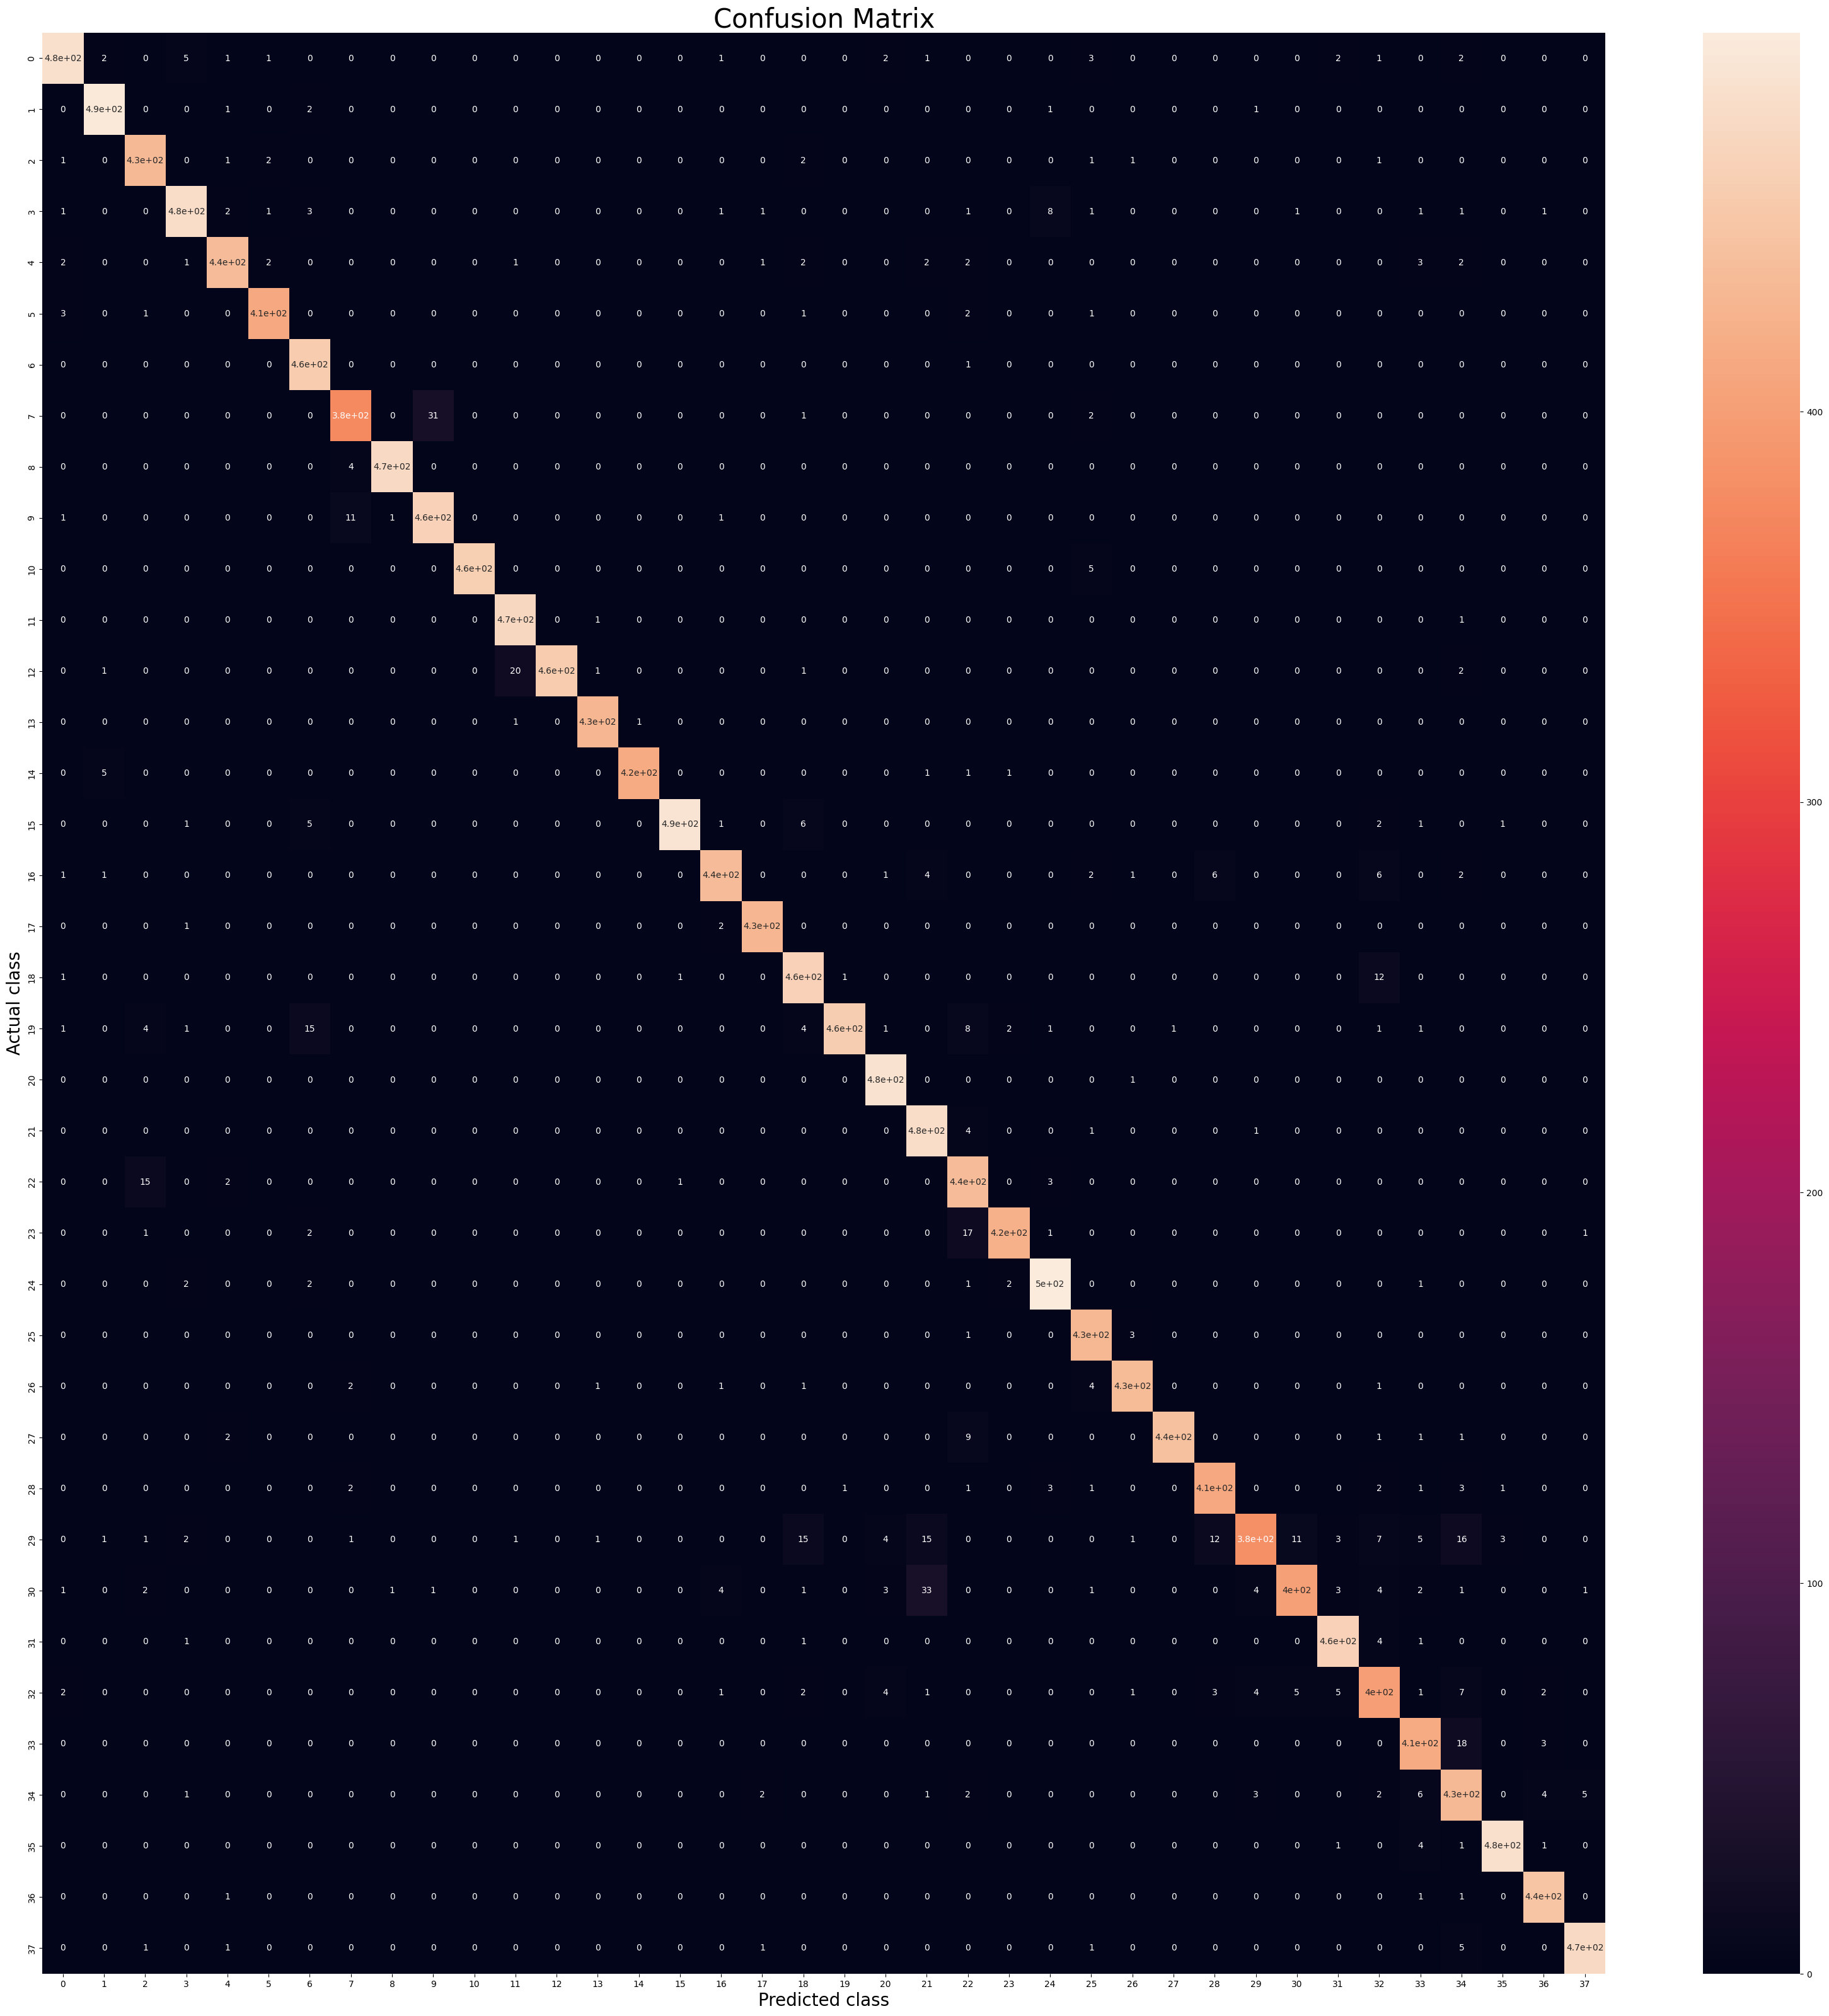

In [25]:
plt.figure(figsize=(40,40))
sns.heatmap(cn,annot=True,annot_kws={'size':10})
plt.xlabel("Predicted class",fontsize=20)
plt.ylabel("Actual class",fontsize=20)
plt.title("Confusion Matrix",fontsize=30)
plt.show()